In [233]:
import numpy as np
import funcoes as fn
import matplotlib.pyplot as plt

# Unidades

## Comprimento

um = 1e-6
nm = 1e-9

## frequência 

GHz = 1e9
THz = 1e12

# Constantes

pi = np.pi
c = 3e8 # m/s
u0 = 4*pi*1e-7
e0 = 1/(36*pi) * 1e-9

lambda0 = 1.55*um
f0 = c/lambda0

k0 = 2*pi/lambda0

# colormaps

cmap1 = plt.cm.viridis
cmap2 = plt.cm.plasma
cmap3 = plt.cm.inferno
cmap4 = plt.cm.magma
cmap5 = plt.cm.coolwarm
cmap6 = plt.cm.turbo
cmap7 = plt.cm.GnBu
cmap8 = plt.cm.winter

cmaps = [cmap1, cmap2, cmap3, cmap4, cmap5, cmap6, cmap7, cmap8]

In [234]:
# Dados da fibra

n1 = 1.4505
n2 = 1.4447

# Frequência normalizada e constante de propagação normalizada #

A frequência normalizada de uma fibra óptica, $V$ é definida como:

$$V=k_0a\sqrt{n^2_1-n^2_2}\,,$$

já a constante de propagação normalizada de um modo, $b$ é definida como:

$$b=\frac{n_{eff}-n_2}{n_1-n_2}\,.$$

A caracterização de uma fibra é feita a partir da curva $b(V)$, que apresenta os modos propagantes em uma fibra em função de sua frequência normalizada.

In [235]:
def a(V):
    return V/(k0*np.sqrt(n1**2-n2**2))

def b(neff):
    num = neff-n2
    den = n1-n2
    return num/den

In [236]:
V_array = np.linspace(1e-3,4,51)
neff_array = np.linspace(1.4448,1.4504,51)
m_lits = np.arange(0,6,1)

a_array = a(V_array)
beta_array = neff_array*k0

raizes_matrix = []
for k in range (0,len(V_array),1):
    a = a_array[k]
    raizes_array2 = [k]
    for m in m_lits:
        raizes_array = fn.retornar_raiz(beta_array, m, a, n1, n2, lambda0)
        if len(raizes_array) != 0:
            for raiz in raizes_array:
                raizes_array2.append(raiz)
        else:
            raizes_array2.append(np.nan)   
    raizes_matrix.append(raizes_array2)

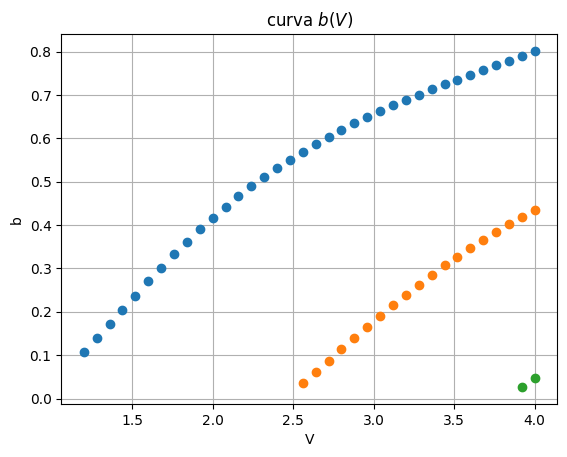

In [237]:
for k in range(len(raizes_matrix)):
  # 1. Pega a linha (ignorando o índice 0) e remove os NaNs
  linha = np.array(raizes_matrix[k][1:], dtype=float)
  raizes_validas = linha[~np.isnan(linha)]

  # 2. Calcula b e ordena do maior para o menor
  b_vals = (raizes_validas - n2) / (n1 - n2)
  b_vals = np.sort(b_vals)[::-1]

  # 3. Remove duplicatas muito próximas (tolerância de 0.01 no eixo b)
  b_unicos = []
  for b in b_vals:
    if not b_unicos or abs(b - b_unicos[-1]) > 0.01:
      b_unicos.append(b)

  # 4. Plota cada curva com sua cor fixa
  for m, b in enumerate(b_unicos):
    cor = f'C{m % 10}'
    plt.plot(V_array[k], b, marker='o', color=cor)

plt.grid(True)
plt.title(r'curva $b(V)$')
plt.xlabel(r'V')
plt.ylabel(r'b')
plt.show()